# XUV Polarimetry

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/07-xray_reflectivity/02-XUV_polarimetry.ipynb)

This example extends the previous one on [resonant magnetic X-ray scattering](#example_resonant_magnetic_xray) by showcasing the ability to simulate with variable incoming and outgoing polarization in the XUV and soft-X-ray spectral range. 

:::{versionadded} 2.4.0
Enable variable/elliptical polarization in {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>`
:::

With that it is possible to extend the simulations beyond common geometries of XMCD and transversal [MOKE](https://en.wikipedia.org/wiki/Magneto-optic_Kerr_effect) (__T-MOKE__) to also probe in longitudinal and polar MOKE geometry, __L-MOKE__ and __P-MOKE__, respectively.

Since polarizing optics are hardly available/feasible in the XUV and soft-X-ray spectral range, L- and P-MOKE rely on the sample reflection itself close to the Brewster angle as polarization analyzer.
Or in other words, the exact Brewster angle relies on the magnetization and polarization-dependent refractive index.

:::{admonition} Reference {cite}`richter2025`
:class: seealso
J. Richter, et al., _Spectroscopic probe of ultrafast magnetization dynamics in the extreme ultraviolet spectral range_, [Phys. Rev. B 111, 214423 (2025)](https://doi.org/10.1103/kjg2-t36b) 
:::

An overview of the different geometries are given in the following sketch form [Richter, et al.](https://doi.org/10.1103/kjg2-t36b):

![L-, T-, and P-MOKE geometries](./XUV_polarimetry.png "L-, T-, and P-MOKE geometries")

Note, that for L- and P-MOKE the linear polarization must be slightly tilted out of the scattering plane.

:::{attention}
In the current example, the polarization angle is referred to as $\alpha$ and __NOT__ $\phi$ as in the sketch from the paper in order to not confuse it with the polar coordinate of the magnetization as otherwise used in the __udkm1Dsim__ toolbox, see [Getting Started](../../getting_started) for details.
There is further 90° offset between both polarization angles.
:::

The following table summarizes the experimental configurations:

|                            | (a) L-MOKE      |  (b) T-MOKE    | (c) P-MOKE |
| -----------:               | :--------:      |  :--------:    | :--------: |
| __magnetization__ $\gamma$ | 90°             | 0°             |     -      |
| __magnetization__ $\phi$   | 90°             | 90°            |     0°     |
| __polarization__ $\alpha$  | $\neq$ 90°       | $=$ 90°         | $\neq$ 90°  |

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In the XUV spectral range, the atomic form factors from {cite:t}`henke1993` are more suitable and can be selected by the keyword `atomic_form_factor_source` in the `Atom` constructor.

In [2]:
Ta = ud.Atom("Ta", atomic_form_factor_source="henke")
Ru = ud.Atom("Ru", atomic_form_factor_source="henke")

Si = ud.Atom("Si", atomic_form_factor_source="henke")
O = ud.Atom("O", atomic_form_factor_source="henke")

SiO2 = ud.AtomMixed("SiO2")
SiO2.add_atom(Si, 0.33)
SiO2.add_atom(O, 0.67)

For the magnetic Fe atom, the measured charge and magnetic form factors at the Fe $M_{2,3}$ edges of {cite:t}`willems2019` are used.

In [3]:
Fe = ud.Atom(
    "Fe",
    magnetization={"r": 1, "phi": 90 * u.deg, "gamma": 180 * u.deg},
    atomic_form_factor_path="./Fe_XUV.cf",
    magnetic_form_factor_path="./Fe_XUV.mf",
)

In [4]:
layer_Ta = ud.AmorphousLayer(
    "Ta",
    "Ta amorphous",
    atom=Ta,
    structural=ud.StructuralParameters(thickness=3 * u.nm, density=16650 * u.kg / u.m**3),
)
layer_Ru = ud.AmorphousLayer(
    "Ru",
    "Ru amorphous",
    atom=Ru,
    structural=ud.StructuralParameters(thickness=2 * u.nm, density=12370 * u.kg / u.m**3),
)
layer_SiO2 = ud.AmorphousLayer(
    "SiO2",
    "SiO2 amorphous",
    atom=SiO2,
    structural=ud.StructuralParameters(thickness=100 * u.nm, density=2650 * u.kg / u.m**3),
)
layer_Fe = ud.AmorphousLayer(
    "Fe",
    "Fe amorphous",
    atom=Fe,
    structural=ud.StructuralParameters(thickness=8 * u.nm, density=7874 * u.kg / u.m**3),
)

The dielectric functions of the layers follow from the atomic and magnetic form factors of their atoms, see the [dielectric example](#example_dielectric).
The optical constants $\delta$ and $\beta$ of the refractive index $n = 1 - \delta + i\beta$ and the magnetic optical constants $\Delta\delta$ and $\Delta\beta$ of the Fe layer show the resonance at its $M_{2,3}$ edges:

In [5]:
for layer in [layer_Ta, layer_Ru, layer_SiO2, layer_Fe]:
    layer.set_dielectric_from_atoms()

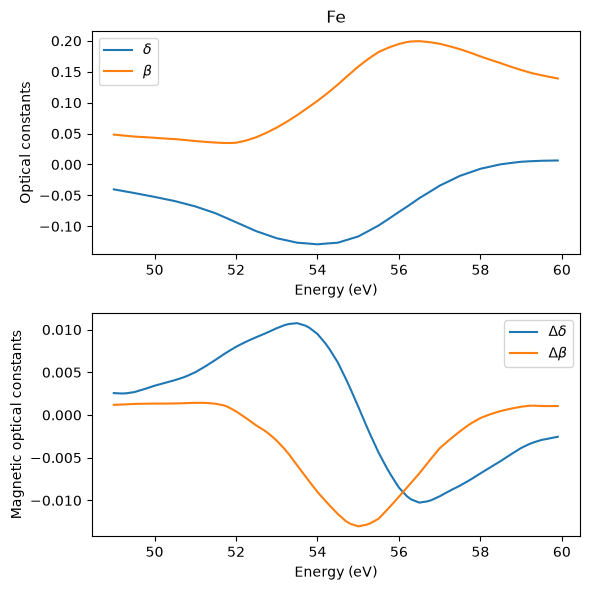

In [6]:
energies = np.r_[49:60:0.1] * u.eV
delta, beta = layer_Fe.get_delta_beta(energies)
delta_mag, beta_mag = layer_Fe.get_delta_beta_mag(energies)

plt.figure(figsize=[6, 6])
plt.subplot(2, 1, 1)
plt.plot(energies, delta, label=r"$\delta$")
plt.plot(energies, beta, label=r"$\beta$")
plt.legend()
plt.xlabel("Energy (eV)")
plt.ylabel("Optical constants")
plt.title("Fe")

plt.subplot(2, 1, 2)
plt.plot(energies, delta_mag, label=r"$\Delta\delta$")
plt.plot(energies, beta_mag, label=r"$\Delta\beta$")
plt.legend()
plt.xlabel("Energy (eV)")
plt.ylabel("Magnetic optical constants")

plt.tight_layout()
plt.show()

In [7]:
S = ud.Structure("Fe MOKE")

S.add_sub_structure(layer_Ru, 1)
S.add_sub_structure(layer_Fe, 1)
S.add_sub_structure(layer_Ta, 1)

# add semi-infinite, static substrate
S.add_substrate(layer_SiO2)

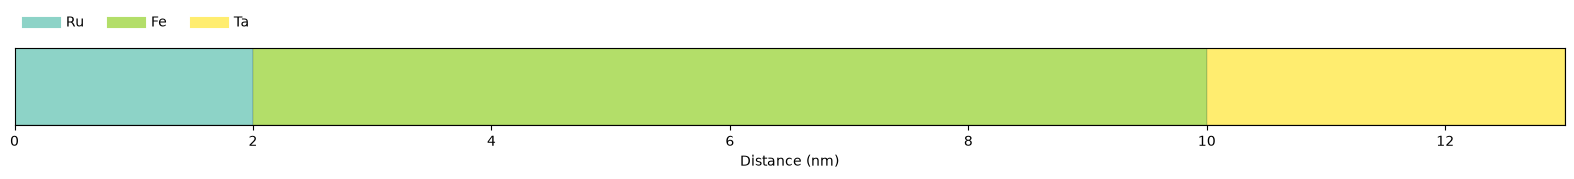

In [8]:
S.visualize()

## Resonant Magnetic XUV Reflectivity

The {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` simulation is set up as in the [resonant magnetic X-ray scattering example](#example_resonant_magnetic_xray), see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.

In [9]:
dyn_mag = ud.Elzo(S, True)
dyn_mag.disp_messages = True
dyn_mag.save_data = False

In [10]:
dyn_mag.energy = 54 * u.eV
dyn_mag.theta = np.r_[45] * u.deg

## Polarization Settings

In all following simulations the analyzer polarization is kept as *unpolarized*, which is equivalent to

    dyn_mag.set_outgoing_polarization("none")

To enable variable/elliptical incoming polarization, the state `"elliptical"` must be given to the {py:meth}`set_incoming_polarization <udkm1Dsim.simulations.scattering.elzo.Elzo.set_incoming_polarization>` method.

In this case a single tuple or list of tuples of the azimuth angle $\alpha$ and the ellipticity $e$ of the polarization can be input.

:::{note}
```{math}
  0° \leq & \alpha \leq +180° \\
  & \alpha = \begin{cases}
    0° & s\text{-polarization}\\
    90° & p\text{-polarization}
\end{cases}\\
& \\
  -1 \leq  & e \leq +1 \\
  & e = \begin{cases}
    -1 &\text{circular left}\\
     0 &\text{linear}\\
    +1 &\text{circular right}
\end{cases}
```
:::

In [11]:
alphas = np.r_[0:180:0.1]
dyn_mag.set_incoming_polarization("elliptical", [(alpha * u.deg, 0) for alpha in alphas])

incoming polarizations set to: elliptical


## T-MOKE

The current experimental configuration already corresponds to the well-known T-MOKE geometry.

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.056264 s


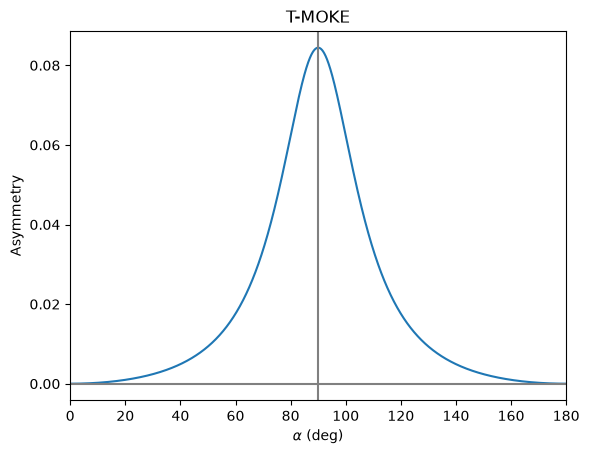

In [12]:
layer_Fe.magnetization = {"phi": 90 * u.deg, "gamma": 180 * u.deg}  # in-plane, s-pol

dyn_mag.theta = np.r_[45] * u.deg

res = dyn_mag.homogeneous_reflectivity_transmissivity()
R, R_phi = res.R, res.R_phi
asym_tmoke = ((R - R_phi) / (R + R_phi)).flatten()

plt.figure()
plt.plot(alphas, asym_tmoke)
plt.axvline(90, color="gray")
plt.axhline(0, color="gray")
plt.xlabel(r"$\alpha$ (deg)")
plt.ylabel("Asymmetry")
plt.xlim(0, 180)
plt.title("T-MOKE")
plt.show()

## L-MOKE

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.078667 s


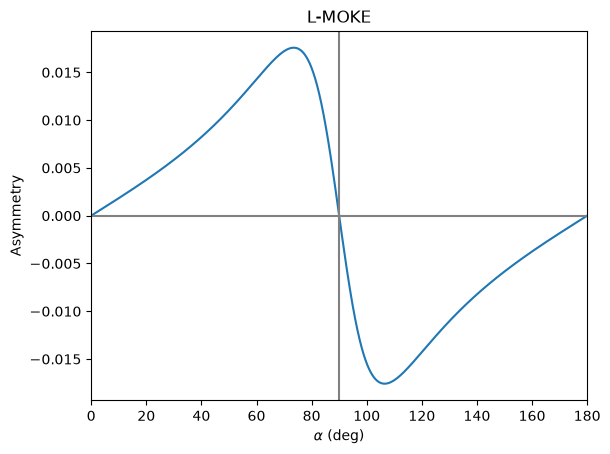

In [13]:
layer_Fe.magnetization = {"phi": 90 * u.deg, "gamma": 90 * u.deg}  # in-plane, p-pol

dyn_mag.theta = np.r_[45] * u.deg

res = dyn_mag.homogeneous_reflectivity_transmissivity()
R, R_phi = res.R, res.R_phi
asym_lmoke = ((R - R_phi) / (R + R_phi)).flatten()

plt.figure()
plt.plot(alphas, asym_lmoke)
plt.axvline(90, color="gray")
plt.axhline(0, color="gray")
plt.xlabel(r"$\alpha$ (deg)")
plt.ylabel("Asymmetry")
plt.xlim(0, 180)
plt.title("L-MOKE")
plt.show()

## P-MOKE

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.053895 s


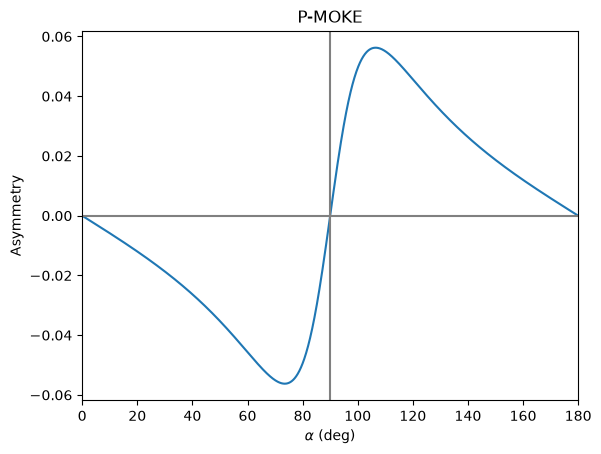

In [14]:
layer_Fe.magnetization = {"phi": 0 * u.deg, "gamma": 0 * u.deg}  # out-of-plane, any

dyn_mag.theta = np.r_[45] * u.deg

res = dyn_mag.homogeneous_reflectivity_transmissivity()
R, R_phi = res.R, res.R_phi
asym_pmoke = ((R - R_phi) / (R + R_phi)).flatten()

plt.figure()
plt.plot(alphas, asym_pmoke)
plt.axvline(90, color="gray")
plt.axhline(0, color="gray")
plt.xlabel(r"$\alpha$ (deg)")
plt.ylabel("Asymmetry")
plt.xlim(0, 180)
plt.title("P-MOKE")
plt.show()

## Comparison

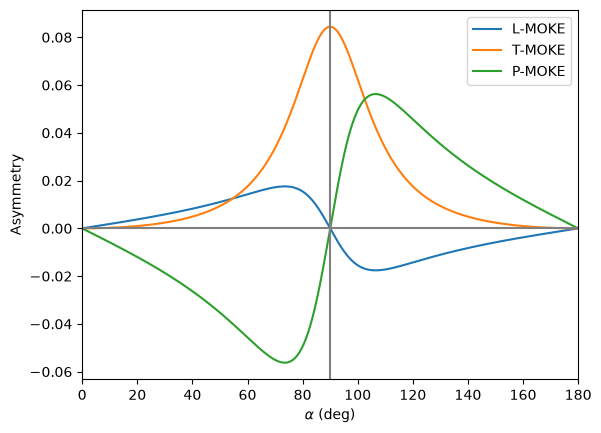

In [15]:
plt.figure()
plt.plot(alphas, asym_lmoke, label="L-MOKE")
plt.plot(alphas, asym_tmoke, label="T-MOKE")
plt.plot(alphas, asym_pmoke, label="P-MOKE")
plt.legend()
plt.axvline(90, color="gray")
plt.axhline(0, color="gray")
plt.xlabel(r"$\alpha$ (deg)")
plt.ylabel("Asymmetry")
plt.xlim(0, 180)
plt.show()

## Gallery plot

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.200547 s


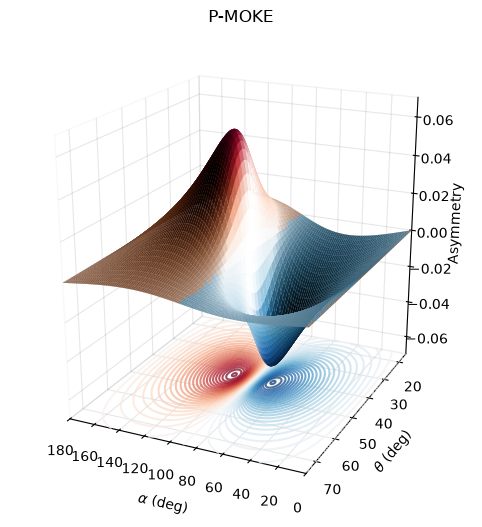

In [16]:
from matplotlib.colors import LightSource  # 3D plotting

dyn_mag.theta = np.r_[15:75:0.1] * u.deg
res = dyn_mag.homogeneous_reflectivity_transmissivity()
asym_pmoke_map = (res.R - res.R_phi) / (res.R + res.R_phi)

fig = plt.figure(figsize=[8, 6])
ax = fig.add_subplot(111, projection="3d")

X, Y = np.meshgrid(alphas, res.quantity("theta", "deg")[0, :].magnitude)
Z = asym_pmoke_map[0, :, :]

ls = LightSource(315, 10)
rgb = ls.shade(Z, cmap=plt.colormaps["RdBu_r"], vert_exag=10, blend_mode="hsv")

ax.plot_surface(
    X, Y, Z, linewidth=0.1, antialiased=True, shade=False, facecolors=rgb, rstride=15, cstride=15
)

ax.contour(X, Y, Z, zdir="z", offset=-0.07, cmap="RdBu_r", levels=50, alpha=0.75)

ax.set_ylabel(r"$\theta$ (deg)")
ax.set_xlabel(r"$\alpha$ (deg)")
ax.set_zlabel("Asymmetry")
ax.set_title("P-MOKE")

ax.set_xlim(0, 180)
ax.set_ylim(15, 75)
ax.set_zlim(-0.07, 0.07)

ax.view_init(
    elev=20.0,
    azim=115,
    roll=0,
)
ax.set_proj_type("persp", focal_length=0.5)  # FOV = 157.4 deg
ax.set_box_aspect((3.5, 4, 4))
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.fill = False
    axis._axinfo["grid"]["color"] = (0.1, 0.1, 0.1, 0.1)  # white grid lines